# Задача 4.8 — Две точки на отрезке

---

## 1. Условие

На отрезке $[a, b]$ наудачу выбирается первая точка с координатой $x$, затем на отрезке $[a, x]$ — вторая точка с координатой $y$. Найдите вероятности событий:

- $A$ — вторая точка ближе к $b$, чем первая к $a$;
- $B$ — расстояние между точками $x$ и $y$ меньше половины длины отрезка;
- $C$ — первая точка ближе ко второй, чем к точке $b$.

Постройте график $p^{\wedge}(A)$ от $N = 150\,000$.

---

## 2. Теоретическая часть

Не ограничивая общности, $a = 0$, $b = 1$. Тогда $x \sim U(0,1)$, а $y \sim U(0, x)$ (условно). Совместная плотность: $f(x, y) = \dfrac{1}{x}$ при $0 \le y \le x \le 1$.

### A: $1 - y < x - 0 \;\Leftrightarrow\; y > 1 - x$

$$
P(A) = \int_{1/2}^{1} \int_{1-x}^{x} \frac{1}{x}\,dy\,dx
= \int_{1/2}^{1} \frac{2x - 1}{x}\,dx
= \left[2x - \ln x\right]_{1/2}^{1} = 1 - 2\cdot\tfrac12 + \ln 2 = \ln 2 - \tfrac12 \approx 0{,}1931.
$$

### B: $|x - y| < \tfrac12 \;\Leftrightarrow\; y > x - \tfrac12$

$$
P(B) = \int_{0}^{1}\int_{\max(0, x-1/2)}^{x} \frac{1}{x}\,dy\,dx
= \int_{0}^{1/2} 1\,dx + \int_{1/2}^{1} \frac{1/2}{x}\,dx
= \frac12 + \frac12\ln 2 \approx 0{,}8466.
$$

### C: $x - y < 1 - x \;\Leftrightarrow\; y > 2x - 1$

При $x \le 1/2$ условие выполнено всегда; при $x > 1/2$ нужно $y > 2x - 1$:

$$
P(C) = \int_{0}^{1/2} 1\,dx + \int_{1/2}^{1} \frac{x - (2x-1)}{x}\,dx
= \frac12 + \int_{1/2}^{1}\left(1 - \frac{x-1}{x}\right)dx
= \frac12 + \int_{1/2}^{1}\frac{1}{x}\,dx - \frac12 = \ln 2 \approx 0{,}6931.
$$

---

## 3. Решение

P(A) ≈ 0.306327  (теор. 1-ln2 = 0.306853)
P(B) ≈ 0.845593  (теор. 1/2+ln2/2 = 0.846574)
P(C) ≈ 0.692760  (теор. ln2 = 0.693147)


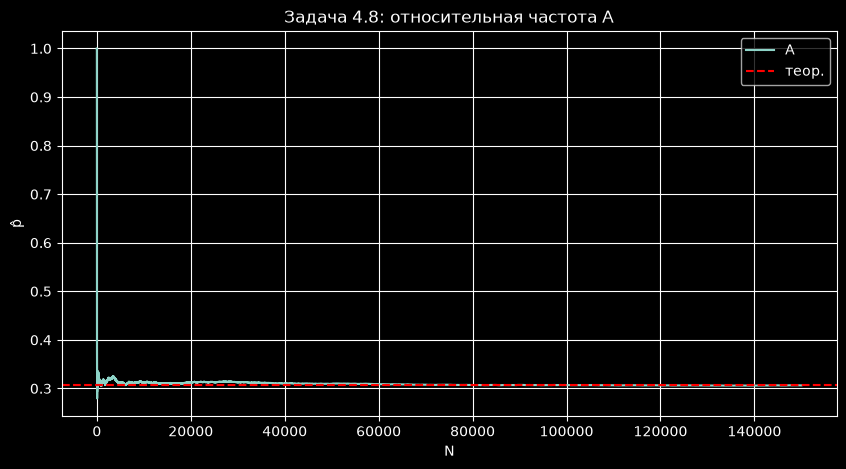

In [2]:
import numpy as np
import matplotlib.pyplot as plt

N = 150_000
rng = np.random.default_rng(seed=7)
x = rng.uniform(0, 1, N)
y = rng.uniform(0, x, N)

A = (1 - y) < x            # вторая ближе к b, чем первая к a
B = np.abs(x - y) < 0.5
C = (x - y) < (1 - x)      # первая ближе ко второй, чем к b

print(f"P(A) ≈ {A.mean():.6f}  (теор. 1-ln2 = {1 - np.log(2):.6f})")
print(f"P(B) ≈ {B.mean():.6f}  (теор. 1/2+ln2/2 = {0.5+0.5*np.log(2):.6f})")
print(f"P(C) ≈ {C.mean():.6f}  (теор. ln2 = {np.log(2):.6f})")

freq = np.cumsum(A) / np.arange(1, N+1)
plt.figure(figsize=(10, 5))
plt.plot(freq, label="A")
plt.axhline(1 - np.log(2), color="r", ls="--", label="теор.")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(); plt.grid(True)
plt.title("Задача 4.8: относительная частота A")
plt.show()